In [1]:

# ============================================================
# HW7 - STEP 1: PERSONAL PARAMETERS AND REPRODUCIBILITY
# ============================================================

import random
import numpy as np
import torch

# Personal parameters
SID4 = 1980
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device selection
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Display parameters
print("=" * 55)
print("HOMEWORK 7 - PERSONAL PARAMETERS")
print("=" * 55)
print(f"SID4   : {SID4}")
print(f"SEED   : {SEED}")
print(f"SLICE  : {SLICE}")
print(f"HP_ID  : {HP_ID}")
print(f"CLS_A  : {CLS_A}")
print(f"CLS_B  : {CLS_B}")
print(f"Device : {device}")
print(f"PyTorch Version : {torch.__version__}")
print("=" * 55)


HOMEWORK 7 - PERSONAL PARAMETERS
SID4   : 1980
SEED   : 1980
SLICE  : 980
HP_ID  : 0
CLS_A  : 0
CLS_B  : 1
Device : cuda
PyTorch Version : 2.11.0+cu130


In [2]:

# ============================================================
# HW7 - STEP 2: PERSONAL PARAMETERS AND REPRODUCIBILITY
# ============================================================

import random
import numpy as np
import torch

# Personal parameters
SID4 = 1980
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Display configuration
print("=" * 60)
print("HOMEWORK 7 - EXPERIMENT CONFIGURATION")
print("=" * 60)

print(f"SID4              : {SID4}")
print(f"SEED              : {SEED}")
print(f"SLICE             : {SLICE}")
print(f"HP_ID             : {HP_ID}")
print(f"CLS_A             : {CLS_A}")
print(f"CLS_B             : {CLS_B}")
print(f"Device            : {device}")
print(f"PyTorch version   : {torch.__version__}")

if torch.cuda.is_available():
    print(f"GPU               : {torch.cuda.get_device_name(0)}")

print("=" * 60)

# Verify parameters
assert SID4 == 1980
assert SEED == 1980
assert SLICE == 980
assert HP_ID == 0
assert CLS_A == 0
assert CLS_B == 1

print("PASS: Personal parameters verified.")


HOMEWORK 7 - EXPERIMENT CONFIGURATION
SID4              : 1980
SEED              : 1980
SLICE             : 980
HP_ID             : 0
CLS_A             : 0
CLS_B             : 1
Device            : cuda
PyTorch version   : 2.11.0+cu130
GPU               : NVIDIA L4
PASS: Personal parameters verified.


In [3]:

# ============================================================
# HW7 - STEP 3: LOAD FASHIONMNIST DATASET
# ============================================================

from torchvision import datasets, transforms

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# FashionMNIST class names
class_names = train_dataset.classes

# Inspect sample
sample_image, sample_label = train_dataset[0]

print("=" * 60)
print("FASHIONMNIST DATASET SUMMARY")
print("=" * 60)

print(f"Training images : {len(train_dataset):,}")
print(f"Testing images  : {len(test_dataset):,}")
print(f"Image shape     : {tuple(sample_image.shape)}")
print(f"Pixel range     : [{sample_image.min():.1f}, {sample_image.max():.1f}]")
print(f"Number of classes: {len(class_names)}")
print(f"Sample label    : {sample_label} ({class_names[sample_label]})")
print(f"Classes         : {class_names}")

# Verify dataset
assert len(train_dataset) == 60000
assert len(test_dataset) == 10000
assert sample_image.shape == (1, 28, 28)
assert len(class_names) == 10

print("=" * 60)
print("PASS: FashionMNIST dataset loaded successfully.")


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.84MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.2MB/s]

FASHIONMNIST DATASET SUMMARY
Training images : 60,000
Testing images  : 10,000
Image shape     : (1, 28, 28)
Pixel range     : [0.0, 1.0]
Number of classes: 10
Sample label    : 9 (Ankle boot)
Classes         : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
PASS: FashionMNIST dataset loaded successfully.


In [4]:

# ============================================================
# HW7 - STEP 4: CREATE DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

# Training configuration
BATCH_SIZE = 128

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Inspect one training batch
images, labels = next(iter(train_loader))

print("=" * 60)
print("FASHIONMNIST DATALOADER SUMMARY")
print("=" * 60)

print(f"Batch size          : {BATCH_SIZE}")
print(f"Training batches    : {len(train_loader)}")
print(f"Testing batches     : {len(test_loader)}")
print(f"Image batch shape   : {tuple(images.shape)}")
print(f"Label batch shape   : {tuple(labels.shape)}")
print(f"Image data type     : {images.dtype}")
print(f"Device selected     : {device}")

# Verification
assert images.shape == (BATCH_SIZE, 1, 28, 28)
assert labels.shape == (BATCH_SIZE,)
assert len(train_loader) == 469
assert len(test_loader) == 79

print("=" * 60)
print("PASS: DataLoaders created successfully.")


FASHIONMNIST DATALOADER SUMMARY
Batch size          : 128
Training batches    : 469
Testing batches     : 79
Image batch shape   : (128, 1, 28, 28)
Label batch shape   : (128,)
Image data type     : torch.float32
Device selected     : cuda
PASS: DataLoaders created successfully.


In [5]:

# ============================================================
# HW7 - STEP 5: FULLY CONNECTED AUTOENCODER ARCHITECTURE
# ============================================================

import torch.nn as nn

class FCAutoencoder(nn.Module):

    def __init__(self, latent_dim=32):
        super().__init__()

        # Encoder: Compress image into latent representation
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        # Decoder: Reconstruct original image
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed


# Initialize model
LATENT_DIM = 32

fc_ae = FCAutoencoder(
    latent_dim=LATENT_DIM
).to(device)

# Count model parameters
total_params = sum(
    p.numel() for p in fc_ae.parameters()
)

# Test forward pass
dummy_input = torch.randn(4, 1, 28, 28).to(device)

with torch.no_grad():
    dummy_output = fc_ae(dummy_input)

print("=" * 60)
print("FULLY CONNECTED AUTOENCODER SUMMARY")
print("=" * 60)

print(fc_ae)
print(f"\nLatent dimension : {LATENT_DIM}")
print(f"Total parameters : {total_params:,}")
print(f"Input shape      : {tuple(dummy_input.shape)}")
print(f"Output shape     : {tuple(dummy_output.shape)}")
print(f"Output range     : [{dummy_output.min():.4f}, {dummy_output.max():.4f}]")

# Verification
assert dummy_output.shape == dummy_input.shape
assert torch.isfinite(dummy_output).all()
assert dummy_output.min() >= 0
assert dummy_output.max() <= 1

print("=" * 60)
print("PASS: FC-AE architecture verified.")


FULLY CONNECTED AUTOENCODER SUMMARY
FCAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
    (6): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)

Latent dimension : 32
Total parameters : 476,720
Input shape      : (4, 1, 28, 28)
Output shape     : (4, 1, 28, 28)
Output range     : [0.4626, 0.5360]
PASS: FC-AE architecture verified.


In [6]:

# ============================================================
# HW7 - STEP 6: FC-AE TRAINING CONFIGURATION
# ============================================================

import torch.optim as optim

# Training hyperparameters
LEARNING_RATE = 0.001
EPOCHS = 20

# Reconstruction loss
criterion = nn.MSELoss(reduction="mean")

# Adam optimizer
optimizer_fc = optim.Adam(
    fc_ae.parameters(),
    lr=LEARNING_RATE
)

# Training history
fc_train_losses = []
fc_test_losses = []

print("=" * 60)
print("FC-AE TRAINING CONFIGURATION")
print("=" * 60)

print(f"Model             : Fully Connected Autoencoder")
print(f"Epochs            : {EPOCHS}")
print(f"Batch size        : {BATCH_SIZE}")
print(f"Learning rate     : {LEARNING_RATE}")
print(f"Optimizer         : Adam")
print(f"Loss function     : Mean Squared Error")
print(f"Latent dimension  : {LATENT_DIM}")
print(f"Training batches  : {len(train_loader)}")
print(f"Testing batches   : {len(test_loader)}")
print(f"Device            : {device}")

# Verification
assert EPOCHS > 0
assert LEARNING_RATE > 0
assert len(fc_train_losses) == 0
assert len(fc_test_losses) == 0

print("=" * 60)
print("PASS: FC-AE training configuration verified.")


FC-AE TRAINING CONFIGURATION
Model             : Fully Connected Autoencoder
Epochs            : 20
Batch size        : 128
Learning rate     : 0.001
Optimizer         : Adam
Loss function     : Mean Squared Error
Latent dimension  : 32
Training batches  : 469
Testing batches   : 79
Device            : cuda
PASS: FC-AE training configuration verified.


In [7]:

# ============================================================
# HW7 - STEP 7: TRAIN AND EVALUATE FC-AE
# ============================================================

import time
from datetime import datetime

# Reset training history
fc_train_losses = []
fc_test_losses = []

print("=" * 70)
print("FC-AE TRAINING STARTED")
print("=" * 70)
print("Start time:", datetime.now().isoformat())
print(f"Device: {device}")
print(f"Epochs: {EPOCHS}")
print("=" * 70)

start_time = time.perf_counter()

for epoch in range(EPOCHS):

    # --------------------------------------------------------
    # BLOCK A: TRAINING
    # --------------------------------------------------------
    fc_ae.train()
    running_train_loss = 0.0

    for images, _ in train_loader:

        images = images.to(device)

        optimizer_fc.zero_grad(set_to_none=True)

        reconstructed = fc_ae(images)

        loss = criterion(reconstructed, images)

        loss.backward()

        optimizer_fc.step()

        running_train_loss += loss.item() * images.size(0)

    avg_train_loss = running_train_loss / len(train_dataset)
    fc_train_losses.append(avg_train_loss)

    # --------------------------------------------------------
    # BLOCK B: EVALUATION
    # --------------------------------------------------------
    fc_ae.eval()
    running_test_loss = 0.0

    with torch.no_grad():

        for images, _ in test_loader:

            images = images.to(device)

            reconstructed = fc_ae(images)

            loss = criterion(reconstructed, images)

            running_test_loss += loss.item() * images.size(0)

    avg_test_loss = running_test_loss / len(test_dataset)
    fc_test_losses.append(avg_test_loss)

    # --------------------------------------------------------
    # BLOCK C: EPOCH RESULTS
    # --------------------------------------------------------
    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train MSE: {avg_train_loss:.6f} | "
        f"Test MSE: {avg_test_loss:.6f}"
    )

# ------------------------------------------------------------
# BLOCK D: FINAL RESULTS
# ------------------------------------------------------------
if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - start_time

print("=" * 70)
print("FC-AE TRAINING COMPLETED")
print("=" * 70)

print(f"Final Train MSE : {fc_train_losses[-1]:.6f}")
print(f"Final Test MSE  : {fc_test_losses[-1]:.6f}")
print(f"Best Test MSE   : {min(fc_test_losses):.6f}")
print(f"Best Epoch      : {fc_test_losses.index(min(fc_test_losses))+1}")
print(f"Total Time      : {total_time:.2f} seconds")
print("End time        :", datetime.now().isoformat())

# ------------------------------------------------------------
# BLOCK E: VERIFICATION
# ------------------------------------------------------------
assert len(fc_train_losses) == EPOCHS
assert len(fc_test_losses) == EPOCHS
assert all(np.isfinite(fc_train_losses))
assert all(np.isfinite(fc_test_losses))

print("PASS: FC-AE training and evaluation verified.")


FC-AE TRAINING STARTED
Start time: 2026-10-20T13:56:20.892249
Device: cuda
Epochs: 20
Epoch [01/20] | Train MSE: 0.038061 | Test MSE: 0.022750
Epoch [02/20] | Train MSE: 0.020401 | Test MSE: 0.018699
Epoch [03/20] | Train MSE: 0.017724 | Test MSE: 0.016921
Epoch [04/20] | Train MSE: 0.016228 | Test MSE: 0.015626
Epoch [05/20] | Train MSE: 0.015119 | Test MSE: 0.014764
Epoch [06/20] | Train MSE: 0.014219 | Test MSE: 0.013974
Epoch [07/20] | Train MSE: 0.013519 | Test MSE: 0.013282
Epoch [08/20] | Train MSE: 0.012947 | Test MSE: 0.012963
Epoch [09/20] | Train MSE: 0.012521 | Test MSE: 0.012414
Epoch [10/20] | Train MSE: 0.012156 | Test MSE: 0.012270
Epoch [11/20] | Train MSE: 0.011807 | Test MSE: 0.011787
Epoch [12/20] | Train MSE: 0.011497 | Test MSE: 0.011466
Epoch [13/20] | Train MSE: 0.011209 | Test MSE: 0.011268
Epoch [14/20] | Train MSE: 0.010955 | Test MSE: 0.010981
Epoch [15/20] | Train MSE: 0.010731 | Test MSE: 0.010757
Epoch [16/20] | Train MSE: 0.010486 | Test MSE: 0.010606
Ep

In [10]:

# ============================================================
# STEP 8.1 - MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Set HW7 folder path
HW7_DIR = "/content/drive/MyDrive/GEN AI HWS/HW7"

# Verify folder
print("Folder exists:", os.path.isdir(HW7_DIR))
print("HW7 path:", HW7_DIR)

assert os.path.isdir(HW7_DIR), "HW7 folder not found"

print("PASS: Google Drive connected successfully.")


Mounted at /content/drive
Folder exists: True
HW7 path: /content/drive/MyDrive/GEN AI HWS/HW7
PASS: Google Drive connected successfully.


In [11]:

# Define Homework 7 Google Drive folder
HW7_DIR = "/content/drive/MyDrive/GEN AI HWS/HW7"

# Verify folder exists
assert os.path.isdir(HW7_DIR), "HW7 folder not found. Mount Google Drive first."

print("PASS: HW7 folder verified.")
print("Folder:", HW7_DIR)


PASS: HW7 folder verified.
Folder: /content/drive/MyDrive/GEN AI HWS/HW7


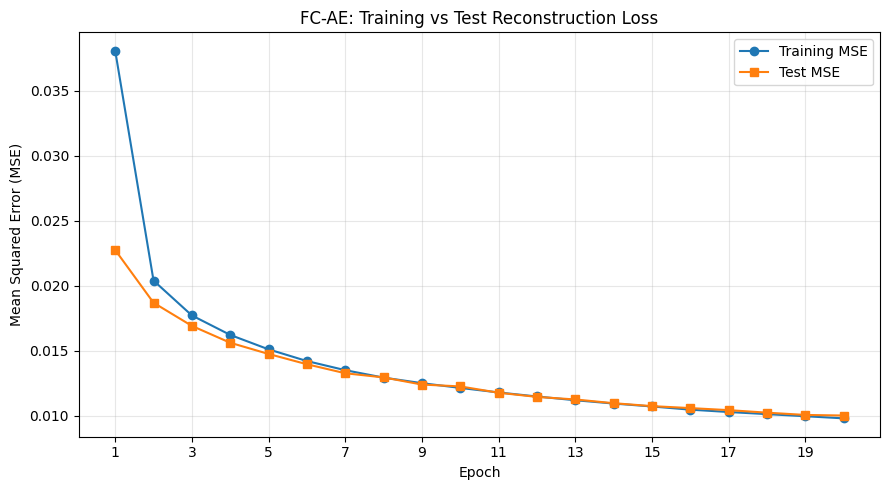

FC-AE LOSS CURVE SUMMARY
Initial Train MSE : 0.038061
Final Train MSE   : 0.009818
Initial Test MSE  : 0.022750
Final Test MSE    : 0.010034
Figure saved to   : /content/drive/MyDrive/GEN AI HWS/HW7/figures/fc_ae_loss_curve.png
PASS: FC-AE loss curves generated and saved.


In [12]:

# ============================================================
# HW7 - STEP 8: FC-AE LOSS CURVES
# ============================================================

import matplotlib.pyplot as plt
import os

# Create figures directory
FIGURES_DIR = os.path.join(HW7_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

# Epoch numbers
epochs_range = range(1, EPOCHS + 1)

# Plot losses
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    fc_train_losses,
    marker="o",
    label="Training MSE"
)

plt.plot(
    epochs_range,
    fc_test_losses,
    marker="s",
    label="Test MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("FC-AE: Training vs Test Reconstruction Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(range(1, EPOCHS + 1, 2))
plt.tight_layout()

# Save figure
figure_path = os.path.join(
    FIGURES_DIR,
    "fc_ae_loss_curve.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Verify saved figure
assert os.path.exists(figure_path)

print("=" * 60)
print("FC-AE LOSS CURVE SUMMARY")
print("=" * 60)
print(f"Initial Train MSE : {fc_train_losses[0]:.6f}")
print(f"Final Train MSE   : {fc_train_losses[-1]:.6f}")
print(f"Initial Test MSE  : {fc_test_losses[0]:.6f}")
print(f"Final Test MSE    : {fc_test_losses[-1]:.6f}")
print(f"Figure saved to   : {figure_path}")
print("PASS: FC-AE loss curves generated and saved.")


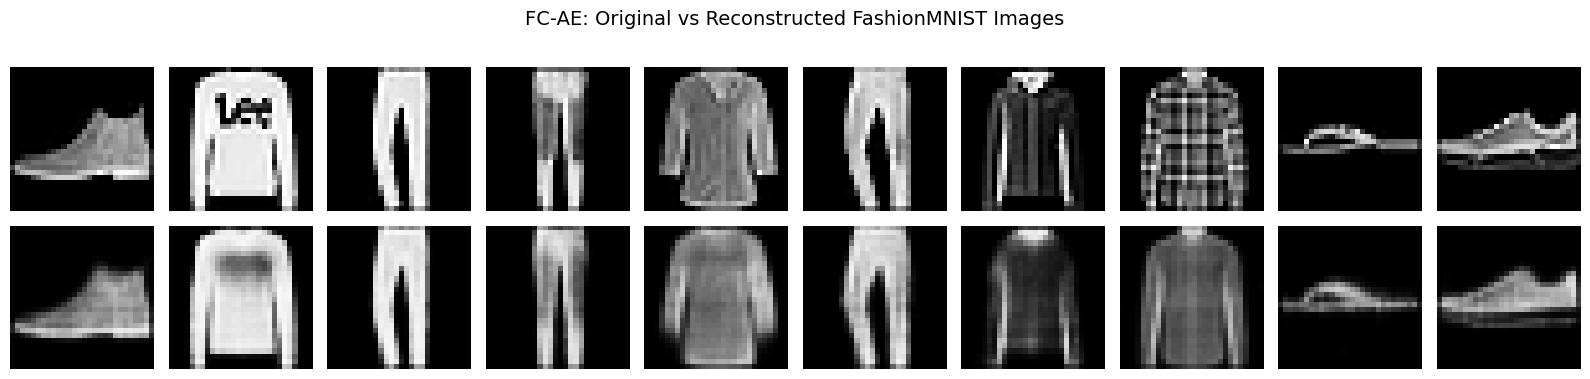

FC-AE RECONSTRUCTION SUMMARY
Images compared       : 10
Sample reconstruction MSE : 0.008933
Figure saved to       : /content/drive/MyDrive/GEN AI HWS/HW7/figures/fc_ae_reconstructions.png
PASS: FC-AE reconstruction visualization completed.


In [13]:

# ============================================================
# HW7 - STEP 9: VISUALIZE FC-AE RECONSTRUCTIONS
# ============================================================

import matplotlib.pyplot as plt
import torch
import os

# Set model to evaluation mode
fc_ae.eval()

# Get a batch of test images
images, labels = next(iter(test_loader))

# Select first 10 images
num_images = 10
original_images = images[:num_images].to(device)

# Reconstruct images
with torch.no_grad():
    reconstructed_images = fc_ae(original_images)

# Move tensors to CPU for visualization
original_images = original_images.cpu()
reconstructed_images = reconstructed_images.cpu()

# Create comparison figure
fig, axes = plt.subplots(
    2, num_images,
    figsize=(16, 4)
)

for i in range(num_images):

    # Original image
    axes[0, i].imshow(
        original_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].axis("off")

    # Reconstructed image
    axes[1, i].imshow(
        reconstructed_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)

plt.suptitle(
    "FC-AE: Original vs Reconstructed FashionMNIST Images",
    fontsize=14
)

plt.tight_layout()

# Save figure
figure_path = os.path.join(
    FIGURES_DIR,
    "fc_ae_reconstructions.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Compute reconstruction MSE for displayed images
sample_mse = torch.mean(
    (original_images - reconstructed_images) ** 2
).item()

print("=" * 60)
print("FC-AE RECONSTRUCTION SUMMARY")
print("=" * 60)
print(f"Images compared       : {num_images}")
print(f"Sample reconstruction MSE : {sample_mse:.6f}")
print(f"Figure saved to       : {figure_path}")

assert os.path.exists(figure_path)
assert reconstructed_images.shape == original_images.shape

print("PASS: FC-AE reconstruction visualization completed.")


In [14]:

# ============================================================
# HW7 - STEP 10: SAVE FC-AE CHECKPOINT AND METRICS
# ============================================================

import os
import json
import csv
import torch
from datetime import datetime

# Create output directories
CHECKPOINT_DIR = os.path.join(HW7_DIR, "checkpoints")
METRICS_DIR = os.path.join(HW7_DIR, "metrics")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# ------------------------------------------------------------
# BLOCK A: SAVE MODEL CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "fc_ae_final.pth"
)

torch.save({
    "model_state_dict": fc_ae.state_dict(),
    "optimizer_state_dict": optimizer_fc.state_dict(),
    "epochs_completed": EPOCHS,
    "latent_dim": LATENT_DIM,
    "seed": SEED,
    "train_losses": fc_train_losses,
    "test_losses": fc_test_losses
}, checkpoint_path)

# ------------------------------------------------------------
# BLOCK B: SAVE METRICS AS JSON
# ------------------------------------------------------------

metrics = {
    "model": "Fully Connected Autoencoder",
    "dataset": "FashionMNIST",
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "latent_dim": LATENT_DIM,
    "total_parameters": total_params,
    "final_train_mse": fc_train_losses[-1],
    "final_test_mse": fc_test_losses[-1],
    "best_test_mse": min(fc_test_losses),
    "best_epoch": fc_test_losses.index(
        min(fc_test_losses)
    ) + 1,
    "training_time_seconds": total_time,
    "sample_reconstruction_mse": sample_mse,
    "saved_at": datetime.now().isoformat()
}

metrics_path = os.path.join(
    METRICS_DIR,
    "fc_ae_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

# ------------------------------------------------------------
# BLOCK C: SAVE EPOCH HISTORY AS CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    METRICS_DIR,
    "fc_ae_training_history.csv"
)

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["epoch", "train_mse", "test_mse"])

    for epoch, (train_loss, test_loss) in enumerate(
        zip(fc_train_losses, fc_test_losses), start=1
    ):
        writer.writerow([epoch, train_loss, test_loss])

# ------------------------------------------------------------
# BLOCK D: VERIFY SAVED FILES
# ------------------------------------------------------------

assert os.path.isfile(checkpoint_path)
assert os.path.isfile(metrics_path)
assert os.path.isfile(csv_path)

saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert saved_checkpoint["epochs_completed"] == 20
assert len(saved_checkpoint["train_losses"]) == 20

print("=" * 65)
print("FC-AE ARTIFACT VERIFICATION")
print("=" * 65)

for path in [checkpoint_path, metrics_path, csv_path]:
    size_mb = os.path.getsize(path) / (1024 ** 2)
    print(f"PASS | {size_mb:.3f} MB | {os.path.basename(path)}")

print("-" * 65)
print(f"Final Train MSE : {metrics['final_train_mse']:.6f}")
print(f"Final Test MSE  : {metrics['final_test_mse']:.6f}")
print(f"Best Epoch      : {metrics['best_epoch']}")
print(f"Training Time   : {metrics['training_time_seconds']:.2f} sec")
print("=" * 65)
print("PASS: FC-AE checkpoint and metrics saved successfully.")


FC-AE ARTIFACT VERIFICATION
PASS | 5.471 MB | fc_ae_final.pth
PASS | 0.000 MB | fc_ae_metrics.json
PASS | 0.001 MB | fc_ae_training_history.csv
-----------------------------------------------------------------
Final Train MSE : 0.009818
Final Test MSE  : 0.010034
Best Epoch      : 20
Training Time   : 85.80 sec
PASS: FC-AE checkpoint and metrics saved successfully.


In [15]:

# ============================================================
# HW7 - STEP 11: VARIATIONAL AUTOENCODER ARCHITECTURE
# ============================================================

import torch
import torch.nn as nn

class VariationalAutoencoder(nn.Module):

    def __init__(self, latent_dim=32):
        super().__init__()

        # BLOCK A: Shared encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        # BLOCK B: Latent distribution parameters
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # BLOCK C: Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    # BLOCK D: Reparameterization trick
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    # BLOCK E: Forward pass
    def forward(self, x):
        h = self.encoder(x)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        z = self.reparameterize(mu, logvar)

        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar


# Initialize VAE
vae = VariationalAutoencoder(
    latent_dim=LATENT_DIM
).to(device)

# Count parameters
vae_params = sum(
    p.numel() for p in vae.parameters()
)

# Test forward pass
vae.eval()

dummy_input = torch.rand(4, 1, 28, 28).to(device)

with torch.no_grad():
    reconstruction, mu, logvar = vae(dummy_input)

print("=" * 60)
print("VARIATIONAL AUTOENCODER SUMMARY")
print("=" * 60)

print(vae)
print(f"\nLatent dimension  : {LATENT_DIM}")
print(f"Total parameters  : {vae_params:,}")
print(f"Input shape       : {tuple(dummy_input.shape)}")
print(f"Output shape      : {tuple(reconstruction.shape)}")
print(f"Mean shape        : {tuple(mu.shape)}")
print(f"Log variance shape: {tuple(logvar.shape)}")
print(f"Output range      : [{reconstruction.min():.4f}, {reconstruction.max():.4f}]")

# Verification
assert reconstruction.shape == dummy_input.shape
assert mu.shape == (4, LATENT_DIM)
assert logvar.shape == (4, LATENT_DIM)
assert torch.isfinite(reconstruction).all()
assert torch.isfinite(mu).all()
assert torch.isfinite(logvar).all()
assert reconstruction.min() >= 0
assert reconstruction.max() <= 1

print("=" * 60)
print("PASS: VAE architecture verified.")


VARIATIONAL AUTOENCODER SUMMARY
VariationalAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=32, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
    (6): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)

Latent dimension  : 32
Total parameters  : 480,848
Input shape       : (4, 1, 28, 28)
Output shape      : (4, 1, 28, 28)
Mean shape        : (4, 32)
Log variance shape: (4, 32)
Output range      : [0.3864, 0.6106]
PASS: VAE architecture verified.


In [16]:

# ============================================================
# HW7 - STEP 12: VAE LOSS AND OPTIMIZER CONFIGURATION
# ============================================================

import torch.nn.functional as F
import torch.optim as optim

# ------------------------------------------------------------
# BLOCK A: TRAINING HYPERPARAMETERS
# ------------------------------------------------------------

VAE_EPOCHS = 20
VAE_LEARNING_RATE = 0.001
BETA = 1.0

# ------------------------------------------------------------
# BLOCK B: VAE LOSS FUNCTION
# ------------------------------------------------------------

def vae_loss_function(reconstructed, original, mu, logvar):

    # Binary cross-entropy reconstruction loss
    reconstruction_loss = F.binary_cross_entropy(
        reconstructed,
        original,
        reduction="sum"
    )

    # KL divergence against standard normal distribution
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Normalize both losses by batch size
    batch_size = original.size(0)

    reconstruction_loss = reconstruction_loss / batch_size
    kl_loss = kl_loss / batch_size

    total_loss = reconstruction_loss + BETA * kl_loss

    return total_loss, reconstruction_loss, kl_loss

# ------------------------------------------------------------
# BLOCK C: ADAM OPTIMIZER
# ------------------------------------------------------------

optimizer_vae = optim.Adam(
    vae.parameters(),
    lr=VAE_LEARNING_RATE
)

# ------------------------------------------------------------
# BLOCK D: TRAINING HISTORY
# ------------------------------------------------------------

vae_train_losses = []
vae_test_losses = []

vae_train_recon_losses = []
vae_test_recon_losses = []

vae_train_kl_losses = []
vae_test_kl_losses = []

# ------------------------------------------------------------
# BLOCK E: VERIFY LOSS FUNCTION
# ------------------------------------------------------------

vae.eval()

with torch.no_grad():
    sample_input = torch.rand(4, 1, 28, 28).to(device)

    sample_recon, sample_mu, sample_logvar = vae(sample_input)

    total, recon, kl = vae_loss_function(
        sample_recon,
        sample_input,
        sample_mu,
        sample_logvar
    )

assert torch.isfinite(total)
assert torch.isfinite(recon)
assert torch.isfinite(kl)
assert recon >= 0
assert kl >= 0

print("=" * 65)
print("VAE TRAINING CONFIGURATION")
print("=" * 65)

print(f"Model                : Variational Autoencoder")
print(f"Epochs               : {VAE_EPOCHS}")
print(f"Batch size           : {BATCH_SIZE}")
print(f"Learning rate        : {VAE_LEARNING_RATE}")
print(f"Optimizer            : Adam")
print(f"Reconstruction loss  : Binary Cross Entropy")
print(f"KL weight (Beta)     : {BETA}")
print(f"Latent dimension     : {LATENT_DIM}")
print(f"Total parameters     : {vae_params:,}")
print(f"Device               : {device}")

print("-" * 65)
print("INITIAL LOSS FUNCTION TEST")
print(f"Total loss           : {total.item():.4f}")
print(f"Reconstruction loss  : {recon.item():.4f}")
print(f"KL divergence        : {kl.item():.4f}")

print("=" * 65)
print("PASS: VAE loss and optimizer configuration verified.")


VAE TRAINING CONFIGURATION
Model                : Variational Autoencoder
Epochs               : 20
Batch size           : 128
Learning rate        : 0.001
Optimizer            : Adam
Reconstruction loss  : Binary Cross Entropy
KL weight (Beta)     : 1.0
Latent dimension     : 32
Total parameters     : 480,848
Device               : cuda
-----------------------------------------------------------------
INITIAL LOSS FUNCTION TEST
Total loss           : 544.4938
Reconstruction loss  : 544.3823
KL divergence        : 0.1116
PASS: VAE loss and optimizer configuration verified.


In [17]:

# ============================================================
# HW7 - STEP 13: TRAIN AND EVALUATE VAE
# ============================================================

import time
import numpy as np
from datetime import datetime

# Reset training history
vae_train_losses = []
vae_test_losses = []

vae_train_recon_losses = []
vae_test_recon_losses = []

vae_train_kl_losses = []
vae_test_kl_losses = []

print("=" * 75)
print("VAE TRAINING STARTED")
print("=" * 75)
print("Start time:", datetime.now().isoformat())
print(f"Device: {device}")
print(f"Epochs: {VAE_EPOCHS}")
print("=" * 75)

if device.type == "cuda":
    torch.cuda.synchronize()

vae_start_time = time.perf_counter()

for epoch in range(VAE_EPOCHS):

    # --------------------------------------------------------
    # BLOCK A: TRAINING
    # --------------------------------------------------------
    vae.train()

    train_total = 0.0
    train_recon = 0.0
    train_kl = 0.0

    for images, _ in train_loader:

        images = images.to(device)

        optimizer_vae.zero_grad(set_to_none=True)

        reconstructed, mu, logvar = vae(images)

        total_loss, recon_loss, kl_loss = vae_loss_function(
            reconstructed, images, mu, logvar
        )

        total_loss.backward()

        optimizer_vae.step()

        batch_size = images.size(0)

        train_total += total_loss.item() * batch_size
        train_recon += recon_loss.item() * batch_size
        train_kl += kl_loss.item() * batch_size

    avg_train_total = train_total / len(train_dataset)
    avg_train_recon = train_recon / len(train_dataset)
    avg_train_kl = train_kl / len(train_dataset)

    vae_train_losses.append(avg_train_total)
    vae_train_recon_losses.append(avg_train_recon)
    vae_train_kl_losses.append(avg_train_kl)

    # --------------------------------------------------------
    # BLOCK B: EVALUATION
    # --------------------------------------------------------
    vae.eval()

    test_total = 0.0
    test_recon = 0.0
    test_kl = 0.0

    with torch.no_grad():

        for images, _ in test_loader:

            images = images.to(device)

            reconstructed, mu, logvar = vae(images)

            total_loss, recon_loss, kl_loss = vae_loss_function(
                reconstructed, images, mu, logvar
            )

            batch_size = images.size(0)

            test_total += total_loss.item() * batch_size
            test_recon += recon_loss.item() * batch_size
            test_kl += kl_loss.item() * batch_size

    avg_test_total = test_total / len(test_dataset)
    avg_test_recon = test_recon / len(test_dataset)
    avg_test_kl = test_kl / len(test_dataset)

    vae_test_losses.append(avg_test_total)
    vae_test_recon_losses.append(avg_test_recon)
    vae_test_kl_losses.append(avg_test_kl)

    # --------------------------------------------------------
    # BLOCK C: PRINT EPOCH RESULTS
    # --------------------------------------------------------
    print(
        f"Epoch [{epoch+1:02d}/{VAE_EPOCHS}] | "
        f"Train: {avg_train_total:.4f} | "
        f"Test: {avg_test_total:.4f} | "
        f"Recon: {avg_test_recon:.4f} | "
        f"KL: {avg_test_kl:.4f}"
    )

# ------------------------------------------------------------
# BLOCK D: FINAL RESULTS
# ------------------------------------------------------------

if device.type == "cuda":
    torch.cuda.synchronize()

vae_training_time = time.perf_counter() - vae_start_time

print("=" * 75)
print("VAE TRAINING COMPLETED")
print("=" * 75)

print(f"Final Train Loss : {vae_train_losses[-1]:.4f}")
print(f"Final Test Loss  : {vae_test_losses[-1]:.4f}")
print(f"Final Test Recon : {vae_test_recon_losses[-1]:.4f}")
print(f"Final Test KL    : {vae_test_kl_losses[-1]:.4f}")
print(f"Best Test Loss   : {min(vae_test_losses):.4f}")
print(f"Best Epoch       : {np.argmin(vae_test_losses) + 1}")
print(f"Training Time    : {vae_training_time:.2f} seconds")
print("End time         :", datetime.now().isoformat())

# ------------------------------------------------------------
# BLOCK E: VERIFICATION
# ------------------------------------------------------------

assert len(vae_train_losses) == VAE_EPOCHS
assert len(vae_test_losses) == VAE_EPOCHS

for history in [
    vae_train_losses,
    vae_test_losses,
    vae_train_recon_losses,
    vae_test_recon_losses,
    vae_train_kl_losses,
    vae_test_kl_losses
]:
    assert len(history) == VAE_EPOCHS
    assert np.isfinite(history).all()

print("=" * 75)
print("PASS: VAE training and evaluation verified.")


VAE TRAINING STARTED
Start time: 2026-10-20T14:48:35.180007
Device: cuda
Epochs: 20
Epoch [01/20] | Train: 301.3703 | Test: 268.0266 | Recon: 255.7491 | KL: 12.2776
Epoch [02/20] | Train: 259.3704 | Test: 256.1385 | Recon: 244.8596 | KL: 11.2788
Epoch [03/20] | Train: 252.0387 | Test: 251.5066 | Recon: 240.4999 | KL: 11.0066
Epoch [04/20] | Train: 248.5599 | Test: 249.2085 | Recon: 238.0036 | KL: 11.2049
Epoch [05/20] | Train: 246.6043 | Test: 247.5520 | Recon: 236.3793 | KL: 11.1727
Epoch [06/20] | Train: 245.2493 | Test: 246.3522 | Recon: 234.8307 | KL: 11.5215
Epoch [07/20] | Train: 244.2526 | Test: 245.4411 | Recon: 233.9777 | KL: 11.4633
Epoch [08/20] | Train: 243.5495 | Test: 244.8338 | Recon: 233.1535 | KL: 11.6803
Epoch [09/20] | Train: 242.9199 | Test: 244.3724 | Recon: 232.1056 | KL: 12.2668
Epoch [10/20] | Train: 242.2805 | Test: 243.8930 | Recon: 231.3322 | KL: 12.5608
Epoch [11/20] | Train: 241.7901 | Test: 243.4409 | Recon: 231.4115 | KL: 12.0294
Epoch [12/20] | Train: 24

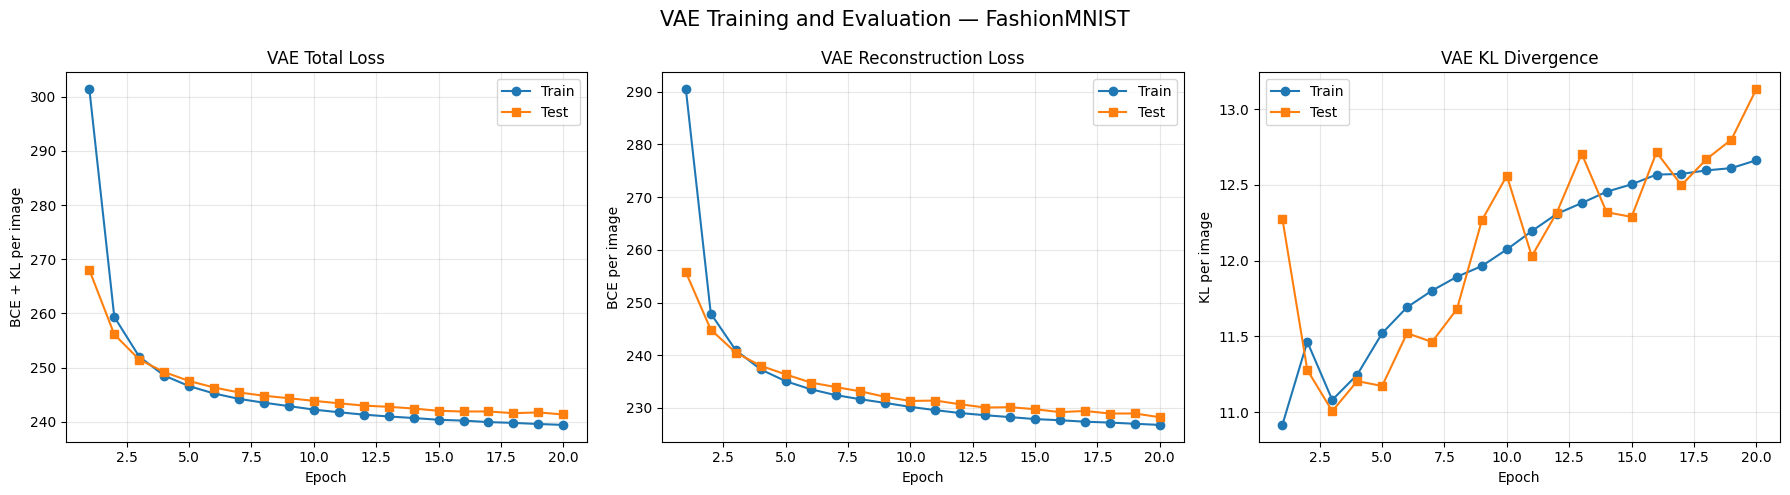

VAE LOSS CURVE SUMMARY
Initial Test Loss  : 268.0266
Final Test Loss    : 241.3774
Final Test Recon   : 228.2453
Final Test KL      : 13.1321
Figure saved to    : /content/drive/MyDrive/GEN AI HWS/HW7/figures/vae_training_curves.png
PASS: VAE training curves generated and saved.


In [18]:

# ============================================================
# HW7 - STEP 14: VAE TRAINING LOSS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

# BLOCK A: Prepare figure directory
FIGURES_DIR = os.path.join(HW7_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

epochs_range = np.arange(1, VAE_EPOCHS + 1)

# BLOCK B: Create three plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Total loss
axes[0].plot(
    epochs_range, vae_train_losses,
    marker="o", label="Train"
)
axes[0].plot(
    epochs_range, vae_test_losses,
    marker="s", label="Test"
)
axes[0].set_title("VAE Total Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE + KL per image")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Reconstruction loss
axes[1].plot(
    epochs_range, vae_train_recon_losses,
    marker="o", label="Train"
)
axes[1].plot(
    epochs_range, vae_test_recon_losses,
    marker="s", label="Test"
)
axes[1].set_title("VAE Reconstruction Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("BCE per image")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: KL divergence
axes[2].plot(
    epochs_range, vae_train_kl_losses,
    marker="o", label="Train"
)
axes[2].plot(
    epochs_range, vae_test_kl_losses,
    marker="s", label="Test"
)
axes[2].set_title("VAE KL Divergence")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("KL per image")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle(
    "VAE Training and Evaluation — FashionMNIST",
    fontsize=15
)
plt.tight_layout()

# BLOCK C: Save figure
figure_path = os.path.join(
    FIGURES_DIR,
    "vae_training_curves.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# BLOCK D: Verify
assert os.path.isfile(figure_path)
assert len(vae_train_losses) == 20
assert len(vae_test_losses) == 20

print("=" * 65)
print("VAE LOSS CURVE SUMMARY")
print("=" * 65)

print(f"Initial Test Loss  : {vae_test_losses[0]:.4f}")
print(f"Final Test Loss    : {vae_test_losses[-1]:.4f}")
print(f"Final Test Recon   : {vae_test_recon_losses[-1]:.4f}")
print(f"Final Test KL      : {vae_test_kl_losses[-1]:.4f}")
print(f"Figure saved to    : {figure_path}")

print("=" * 65)
print("PASS: VAE training curves generated and saved.")


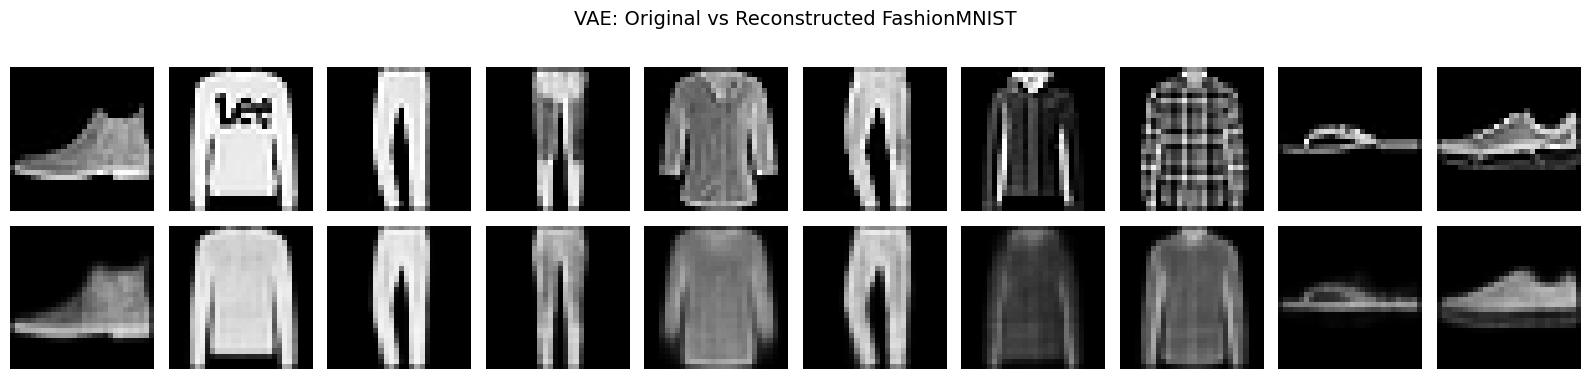

VAE RECONSTRUCTION SUMMARY
Images compared           : 10
Sample reconstruction MSE : 0.014696
Reconstruction method     : Latent mean (deterministic)
Figure saved to           : /content/drive/MyDrive/GEN AI HWS/HW7/figures/vae_reconstructions.png
PASS: VAE reconstruction visualization completed.


In [19]:

# ============================================================
# HW7 - STEP 15: VAE RECONSTRUCTION VISUALIZATION
# ============================================================

import torch
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# BLOCK A: SELECT TEST IMAGES
# ------------------------------------------------------------

vae.eval()

images, labels = next(iter(test_loader))

num_images = 10
original_images = images[:num_images].to(device)

# ------------------------------------------------------------
# BLOCK B: RECONSTRUCT USING LATENT MEAN
# ------------------------------------------------------------

with torch.no_grad():

    encoded = vae.encoder(original_images)

    mu = vae.fc_mu(encoded)

    reconstructed_images = vae.decoder(mu)

# Move to CPU
original_cpu = original_images.cpu()
reconstructed_cpu = reconstructed_images.cpu()

# ------------------------------------------------------------
# BLOCK C: VISUALIZE IMAGES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, num_images,
    figsize=(16, 4)
)

for i in range(num_images):

    axes[0, i].imshow(
        original_cpu[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_cpu[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("VAE Recon", fontsize=12)

plt.suptitle(
    "VAE: Original vs Reconstructed FashionMNIST",
    fontsize=14
)

plt.tight_layout()

# ------------------------------------------------------------
# BLOCK D: SAVE FIGURE
# ------------------------------------------------------------

figure_path = os.path.join(
    FIGURES_DIR,
    "vae_reconstructions.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# BLOCK E: CALCULATE MSE AND VERIFY
# ------------------------------------------------------------

vae_sample_mse = torch.mean(
    (original_cpu - reconstructed_cpu) ** 2
).item()

assert os.path.isfile(figure_path)
assert reconstructed_cpu.shape == original_cpu.shape
assert torch.isfinite(reconstructed_cpu).all()

print("=" * 65)
print("VAE RECONSTRUCTION SUMMARY")
print("=" * 65)

print(f"Images compared           : {num_images}")
print(f"Sample reconstruction MSE : {vae_sample_mse:.6f}")
print(f"Reconstruction method     : Latent mean (deterministic)")
print(f"Figure saved to           : {figure_path}")

print("=" * 65)
print("PASS: VAE reconstruction visualization completed.")


In [20]:

# ============================================================
# HW7 - STEP 16: SAVE VAE CHECKPOINT AND METRICS
# ============================================================

import os
import json
import csv
import torch
import numpy as np
from datetime import datetime

# Create directories
CHECKPOINT_DIR = os.path.join(HW7_DIR, "checkpoints")
METRICS_DIR = os.path.join(HW7_DIR, "metrics")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# ------------------------------------------------------------
# BLOCK A: SAVE VAE CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "vae_final.pth"
)

torch.save({
    "model_state_dict": vae.state_dict(),
    "optimizer_state_dict": optimizer_vae.state_dict(),
    "epochs_completed": VAE_EPOCHS,
    "latent_dim": LATENT_DIM,
    "seed": SEED,
    "beta": BETA,
    "train_losses": vae_train_losses,
    "test_losses": vae_test_losses,
    "train_recon_losses": vae_train_recon_losses,
    "test_recon_losses": vae_test_recon_losses,
    "train_kl_losses": vae_train_kl_losses,
    "test_kl_losses": vae_test_kl_losses
}, checkpoint_path)

# ------------------------------------------------------------
# BLOCK B: SAVE METRICS JSON
# ------------------------------------------------------------

vae_metrics = {
    "model": "Variational Autoencoder",
    "dataset": "FashionMNIST",
    "seed": SEED,
    "epochs": VAE_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": VAE_LEARNING_RATE,
    "latent_dim": LATENT_DIM,
    "beta": BETA,
    "total_parameters": vae_params,
    "final_train_loss": vae_train_losses[-1],
    "final_test_loss": vae_test_losses[-1],
    "final_test_reconstruction_bce": vae_test_recon_losses[-1],
    "final_test_kl": vae_test_kl_losses[-1],
    "best_test_loss": min(vae_test_losses),
    "best_epoch": int(np.argmin(vae_test_losses) + 1),
    "training_time_seconds": vae_training_time,
    "sample_reconstruction_mse": vae_sample_mse,
    "reconstruction_method": "latent_mean",
    "saved_at": datetime.now().isoformat()
}

metrics_path = os.path.join(
    METRICS_DIR,
    "vae_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(vae_metrics, f, indent=4)

# ------------------------------------------------------------
# BLOCK C: SAVE EPOCH HISTORY CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    METRICS_DIR,
    "vae_training_history.csv"
)

with open(csv_path, "w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "epoch",
        "train_total",
        "test_total",
        "train_reconstruction_bce",
        "test_reconstruction_bce",
        "train_kl",
        "test_kl"
    ])

    for i in range(VAE_EPOCHS):
        writer.writerow([
            i + 1,
            vae_train_losses[i],
            vae_test_losses[i],
            vae_train_recon_losses[i],
            vae_test_recon_losses[i],
            vae_train_kl_losses[i],
            vae_test_kl_losses[i]
        ])

# ------------------------------------------------------------
# BLOCK D: VERIFY SAVED ARTIFACTS
# ------------------------------------------------------------

assert os.path.isfile(checkpoint_path)
assert os.path.isfile(metrics_path)
assert os.path.isfile(csv_path)

saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert saved_checkpoint["epochs_completed"] == 20
assert len(saved_checkpoint["train_losses"]) == 20
assert len(saved_checkpoint["test_losses"]) == 20

print("=" * 65)
print("VAE ARTIFACT VERIFICATION")
print("=" * 65)

for path in [checkpoint_path, metrics_path, csv_path]:
    size_mb = os.path.getsize(path) / (1024 ** 2)
    print(f"PASS | {size_mb:.3f} MB | {os.path.basename(path)}")

print("-" * 65)

print(f"Final Train Loss : {vae_metrics['final_train_loss']:.4f}")
print(f"Final Test Loss  : {vae_metrics['final_test_loss']:.4f}")
print(f"Test Recon BCE   : {vae_metrics['final_test_reconstruction_bce']:.4f}")
print(f"Test KL          : {vae_metrics['final_test_kl']:.4f}")
print(f"Best Epoch       : {vae_metrics['best_epoch']}")
print(f"Training Time    : {vae_metrics['training_time_seconds']:.2f} sec")

print("=" * 65)
print("PASS: VAE checkpoint and metrics saved successfully.")


VAE ARTIFACT VERIFICATION
PASS | 5.521 MB | vae_final.pth
PASS | 0.001 MB | vae_metrics.json
PASS | 0.002 MB | vae_training_history.csv
-----------------------------------------------------------------
Final Train Loss : 239.4515
Final Test Loss  : 241.3774
Test Recon BCE   : 228.2453
Test KL          : 13.1321
Best Epoch       : 20
Training Time    : 87.08 sec
PASS: VAE checkpoint and metrics saved successfully.


In [21]:

# ============================================================
# HW7 - STEP 17: FC-AE VS VAE FULL TEST SET COMPARISON
# ============================================================

import torch
import numpy as np
import json
import os

# ------------------------------------------------------------
# BLOCK A: SET MODELS TO EVALUATION MODE
# ------------------------------------------------------------

fc_ae.eval()
vae.eval()

fc_total_squared_error = 0.0
vae_total_squared_error = 0.0
total_pixels = 0

# ------------------------------------------------------------
# BLOCK B: EVALUATE BOTH MODELS
# ------------------------------------------------------------

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        # FC-AE reconstruction
        fc_reconstructed = fc_ae(images)

        # VAE deterministic reconstruction using latent mean
        encoded = vae.encoder(images)
        mu = vae.fc_mu(encoded)
        vae_reconstructed = vae.decoder(mu)

        # Accumulate squared errors
        fc_total_squared_error += torch.sum(
            (fc_reconstructed - images) ** 2
        ).item()

        vae_total_squared_error += torch.sum(
            (vae_reconstructed - images) ** 2
        ).item()

        total_pixels += images.numel()

# ------------------------------------------------------------
# BLOCK C: CALCULATE FULL TEST SET MSE
# ------------------------------------------------------------

fc_full_test_mse = fc_total_squared_error / total_pixels
vae_full_test_mse = vae_total_squared_error / total_pixels

mse_difference = vae_full_test_mse - fc_full_test_mse

if fc_full_test_mse < vae_full_test_mse:
    better_model = "FC-AE"
elif vae_full_test_mse < fc_full_test_mse:
    better_model = "VAE"
else:
    better_model = "Tie"

# ------------------------------------------------------------
# BLOCK D: DISPLAY COMPARISON
# ------------------------------------------------------------

print("=" * 65)
print("FC-AE VS VAE - FULL FASHIONMNIST TEST SET")
print("=" * 65)

print(f"Test images evaluated : {len(test_dataset):,}")
print(f"Total pixels evaluated: {total_pixels:,}")
print(f"FC-AE Test MSE        : {fc_full_test_mse:.6f}")
print(f"VAE Test MSE          : {vae_full_test_mse:.6f}")
print(f"MSE difference        : {mse_difference:.6f}")
print(f"Lower MSE model       : {better_model}")

print("-" * 65)

# ------------------------------------------------------------
# BLOCK E: SAVE COMPARISON METRICS
# ------------------------------------------------------------

comparison_metrics = {
    "dataset": "FashionMNIST",
    "test_images": len(test_dataset),
    "metric": "pixel_mean_squared_error",
    "vae_reconstruction_method": "latent_mean",
    "fc_ae_test_mse": fc_full_test_mse,
    "vae_test_mse": vae_full_test_mse,
    "mse_difference_vae_minus_fc": mse_difference,
    "lower_mse_model": better_model
}

comparison_path = os.path.join(
    METRICS_DIR,
    "fc_ae_vs_vae_comparison.json"
)

with open(comparison_path, "w") as f:
    json.dump(comparison_metrics, f, indent=4)

# ------------------------------------------------------------
# BLOCK F: VERIFICATION
# ------------------------------------------------------------

assert total_pixels == len(test_dataset) * 28 * 28
assert np.isfinite(fc_full_test_mse)
assert np.isfinite(vae_full_test_mse)
assert fc_full_test_mse >= 0
assert vae_full_test_mse >= 0
assert os.path.isfile(comparison_path)

print(f"Comparison saved to   : {comparison_path}")
print("=" * 65)
print("PASS: Full test set comparison completed.")


FC-AE VS VAE - FULL FASHIONMNIST TEST SET
Test images evaluated : 10,000
Total pixels evaluated: 7,840,000
FC-AE Test MSE        : 0.010034
VAE Test MSE          : 0.014975
MSE difference        : 0.004940
Lower MSE model       : FC-AE
-----------------------------------------------------------------
Comparison saved to   : /content/drive/MyDrive/GEN AI HWS/HW7/metrics/fc_ae_vs_vae_comparison.json
PASS: Full test set comparison completed.


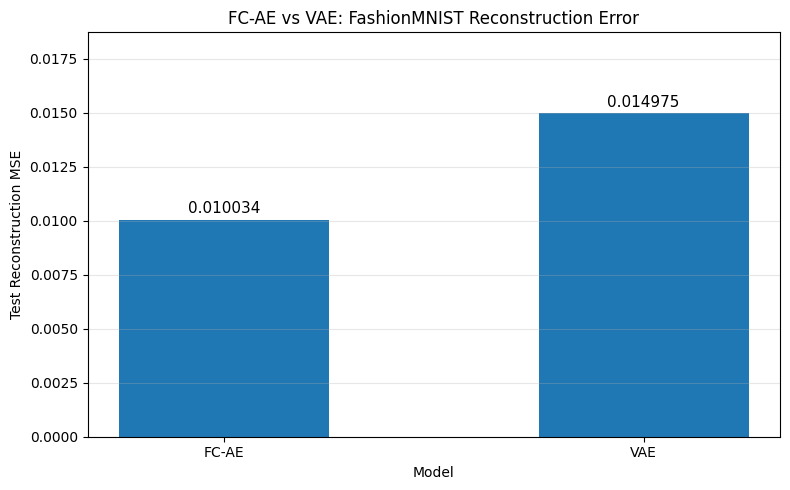

FC-AE VS VAE RECONSTRUCTION COMPARISON
FC-AE Test MSE       : 0.010034
VAE Test MSE         : 0.014975
FC-AE Lower MSE By   : 32.99%
Figure saved to      : /content/drive/MyDrive/GEN AI HWS/HW7/figures/fc_ae_vs_vae_mse_comparison.png
PASS: Model comparison chart generated and saved.


In [22]:

# ============================================================
# HW7 - STEP 18: FC-AE VS VAE COMPARISON CHART
# ============================================================

import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# BLOCK A: PREPARE COMPARISON DATA
# ------------------------------------------------------------

models = ["FC-AE", "VAE"]

mse_values = [
    fc_full_test_mse,
    vae_full_test_mse
]

# ------------------------------------------------------------
# BLOCK B: CREATE BAR CHART
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    mse_values,
    width=0.5
)

plt.ylabel("Test Reconstruction MSE")
plt.xlabel("Model")
plt.title("FC-AE vs VAE: FashionMNIST Reconstruction Error")

plt.ylim(0, max(mse_values) * 1.25)

for bar, value in zip(bars, mse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(mse_values) * 0.02,
        f"{value:.6f}",
        ha="center",
        fontsize=11
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# ------------------------------------------------------------
# BLOCK C: SAVE FIGURE
# ------------------------------------------------------------

comparison_figure_path = os.path.join(
    FIGURES_DIR,
    "fc_ae_vs_vae_mse_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# BLOCK D: CALCULATE RELATIVE DIFFERENCE
# ------------------------------------------------------------

relative_improvement = (
    (vae_full_test_mse - fc_full_test_mse)
    / vae_full_test_mse
) * 100

print("=" * 65)
print("FC-AE VS VAE RECONSTRUCTION COMPARISON")
print("=" * 65)

print(f"FC-AE Test MSE       : {fc_full_test_mse:.6f}")
print(f"VAE Test MSE         : {vae_full_test_mse:.6f}")
print(f"FC-AE Lower MSE By   : {relative_improvement:.2f}%")
print(f"Figure saved to      : {comparison_figure_path}")

assert os.path.isfile(comparison_figure_path)

print("=" * 65)
print("PASS: Model comparison chart generated and saved.")


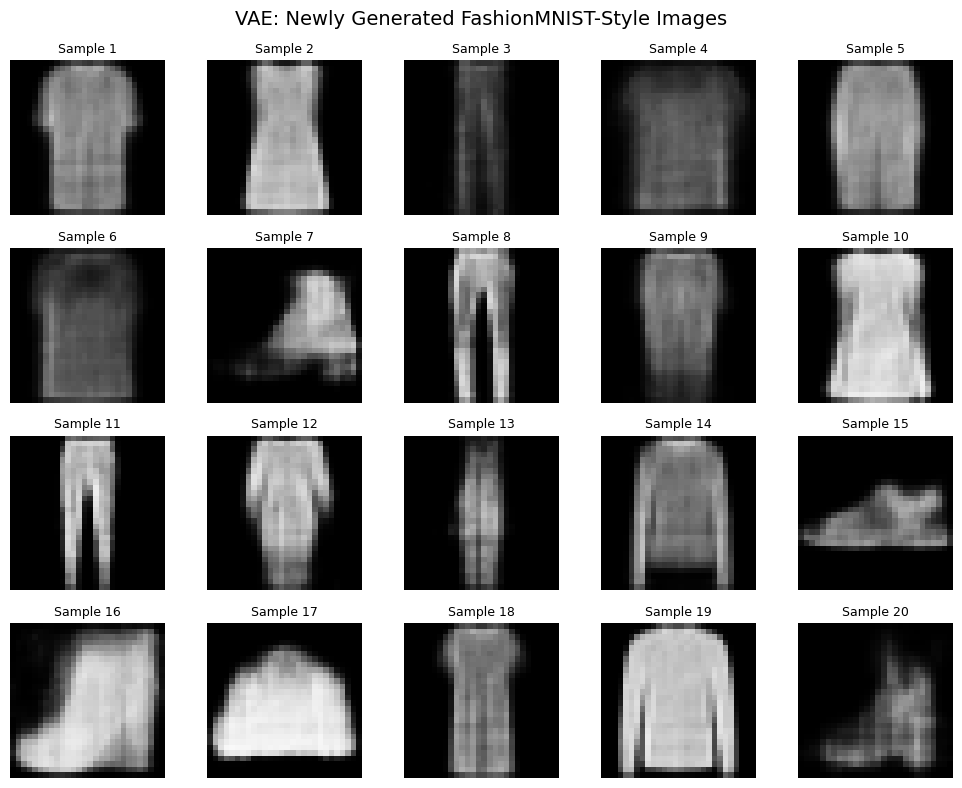

VAE IMAGE GENERATION SUMMARY
Images generated     : 20
Latent dimension     : 32
Sampling distribution: Standard Normal N(0, I)
Generated image shape: (20, 1, 28, 28)
Pixel range          : [0.0000, 0.9747]
Figure saved to      : /content/drive/MyDrive/GEN AI HWS/HW7/figures/vae_generated_images.png
PASS: VAE image generation completed successfully.


In [23]:

# ============================================================
# HW7 - STEP 19: GENERATE NEW IMAGES USING VAE
# ============================================================

import torch
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# BLOCK A: CONFIGURE IMAGE GENERATION
# ------------------------------------------------------------

vae.eval()

NUM_GENERATED = 20

# Independent random generator for reproducibility
generator = torch.Generator(device="cpu")
generator.manual_seed(SEED + 19)

# ------------------------------------------------------------
# BLOCK B: SAMPLE FROM LATENT SPACE
# ------------------------------------------------------------

with torch.no_grad():

    # Sample from standard normal distribution
    z = torch.randn(
        NUM_GENERATED,
        LATENT_DIM,
        generator=generator
    ).to(device)

    # Decode latent vectors into images
    generated_images = vae.decoder(z)

# Move images to CPU
generated_images = generated_images.cpu()

# ------------------------------------------------------------
# BLOCK C: VISUALIZE GENERATED IMAGES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 5,
    figsize=(10, 8)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Sample {i+1}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "VAE: Newly Generated FashionMNIST-Style Images",
    fontsize=14
)

plt.tight_layout()

# ------------------------------------------------------------
# BLOCK D: SAVE GENERATED IMAGES
# ------------------------------------------------------------

figure_path = os.path.join(
    FIGURES_DIR,
    "vae_generated_images.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# BLOCK E: VERIFY GENERATION
# ------------------------------------------------------------

assert generated_images.shape == (20, 1, 28, 28)
assert torch.isfinite(generated_images).all()
assert generated_images.min() >= 0
assert generated_images.max() <= 1
assert os.path.isfile(figure_path)

print("=" * 65)
print("VAE IMAGE GENERATION SUMMARY")
print("=" * 65)

print(f"Images generated     : {NUM_GENERATED}")
print(f"Latent dimension     : {LATENT_DIM}")
print(f"Sampling distribution: Standard Normal N(0, I)")
print(f"Generated image shape: {tuple(generated_images.shape)}")
print(f"Pixel range          : [{generated_images.min():.4f}, {generated_images.max():.4f}]")
print(f"Figure saved to      : {figure_path}")

print("=" * 65)
print("PASS: VAE image generation completed successfully.")


CLASS-WISE RECONSTRUCTION ERROR COMPARISON
      Class  Test Images  FC-AE MSE  VAE MSE
T-shirt/top         1000   0.009094 0.014205
    Trouser         1000   0.004761 0.007871
   Pullover         1000   0.008963 0.014230
      Dress         1000   0.008971 0.013893
       Coat         1000   0.008485 0.013162
     Sandal         1000   0.015488 0.022542
      Shirt         1000   0.010072 0.014468
    Sneaker         1000   0.007544 0.011727
        Bag         1000   0.016613 0.022260
 Ankle boot         1000   0.010351 0.015388


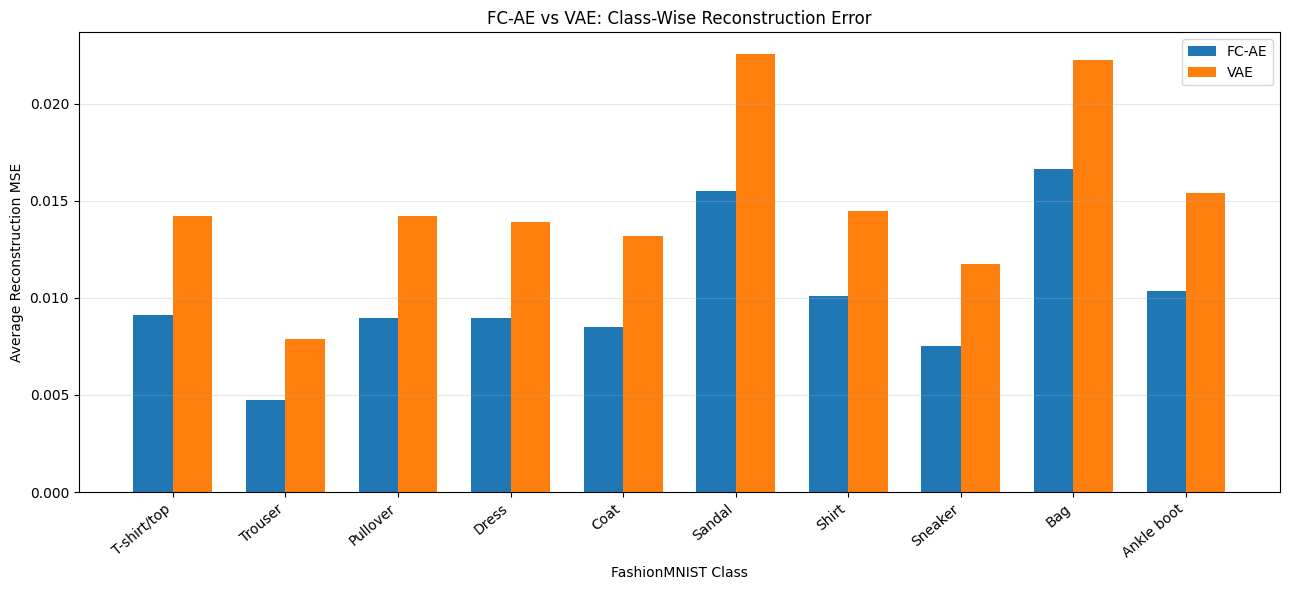

ERROR ANALYSIS SUMMARY
Highest FC-AE error class: Bag
Highest VAE error class: Sandal
Lowest FC-AE error class: Trouser
Lowest VAE error class: Trouser
Figure saved: /content/drive/MyDrive/GEN AI HWS/HW7/figures/class_wise_reconstruction_mse.png
CSV saved   : /content/drive/MyDrive/GEN AI HWS/HW7/metrics/class_wise_reconstruction_mse.csv
PASS: Class-wise reconstruction error analysis completed.


In [24]:

# ============================================================
# HW7 - STEP 20: CLASS-WISE RECONSTRUCTION ERROR ANALYSIS
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# BLOCK A: INITIALIZE ERROR STORAGE
# ------------------------------------------------------------

fc_ae.eval()
vae.eval()

fc_class_errors = {i: [] for i in range(10)}
vae_class_errors = {i: [] for i in range(10)}

# ------------------------------------------------------------
# BLOCK B: CALCULATE PER-IMAGE RECONSTRUCTION MSE
# ------------------------------------------------------------

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # FC-AE reconstruction
        fc_recon = fc_ae(images)

        # VAE deterministic reconstruction
        h = vae.encoder(images)
        mu = vae.fc_mu(h)
        vae_recon = vae.decoder(mu)

        # Calculate MSE separately for each image
        fc_errors = (
            (fc_recon - images) ** 2
        ).mean(dim=(1, 2, 3)).cpu().numpy()

        vae_errors = (
            (vae_recon - images) ** 2
        ).mean(dim=(1, 2, 3)).cpu().numpy()

        for label, fc_err, vae_err in zip(
            labels.numpy(), fc_errors, vae_errors
        ):
            fc_class_errors[int(label)].append(float(fc_err))
            vae_class_errors[int(label)].append(float(vae_err))

# ------------------------------------------------------------
# BLOCK C: CREATE CLASS-WISE METRICS TABLE
# ------------------------------------------------------------

results = []

for i, class_name in enumerate(class_names):

    results.append({
        "Class": class_name,
        "Test Images": len(fc_class_errors[i]),
        "FC-AE MSE": np.mean(fc_class_errors[i]),
        "VAE MSE": np.mean(vae_class_errors[i])
    })

class_df = pd.DataFrame(results)

print("=" * 75)
print("CLASS-WISE RECONSTRUCTION ERROR COMPARISON")
print("=" * 75)

print(class_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# ------------------------------------------------------------
# BLOCK D: VISUALIZE CLASS-WISE ERRORS
# ------------------------------------------------------------

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    class_df["FC-AE MSE"],
    width,
    label="FC-AE"
)

plt.bar(
    x + width / 2,
    class_df["VAE MSE"],
    width,
    label="VAE"
)

plt.xticks(x, class_names, rotation=40, ha="right")
plt.ylabel("Average Reconstruction MSE")
plt.xlabel("FashionMNIST Class")
plt.title("FC-AE vs VAE: Class-Wise Reconstruction Error")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "class_wise_reconstruction_mse.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# BLOCK E: SAVE METRICS AND VERIFY
# ------------------------------------------------------------

csv_path = os.path.join(
    METRICS_DIR,
    "class_wise_reconstruction_mse.csv"
)

class_df.to_csv(csv_path, index=False)

assert len(class_df) == 10
assert class_df["Test Images"].sum() == 10000
assert np.isfinite(class_df[["FC-AE MSE", "VAE MSE"]].values).all()
assert os.path.isfile(csv_path)
assert os.path.isfile(figure_path)

print("=" * 75)
print("ERROR ANALYSIS SUMMARY")
print("=" * 75)

print("Highest FC-AE error class:",
      class_df.loc[class_df["FC-AE MSE"].idxmax(), "Class"])

print("Highest VAE error class:",
      class_df.loc[class_df["VAE MSE"].idxmax(), "Class"])

print("Lowest FC-AE error class:",
      class_df.loc[class_df["FC-AE MSE"].idxmin(), "Class"])

print("Lowest VAE error class:",
      class_df.loc[class_df["VAE MSE"].idxmin(), "Class"])

print(f"Figure saved: {figure_path}")
print(f"CSV saved   : {csv_path}")

print("PASS: Class-wise reconstruction error analysis completed.")


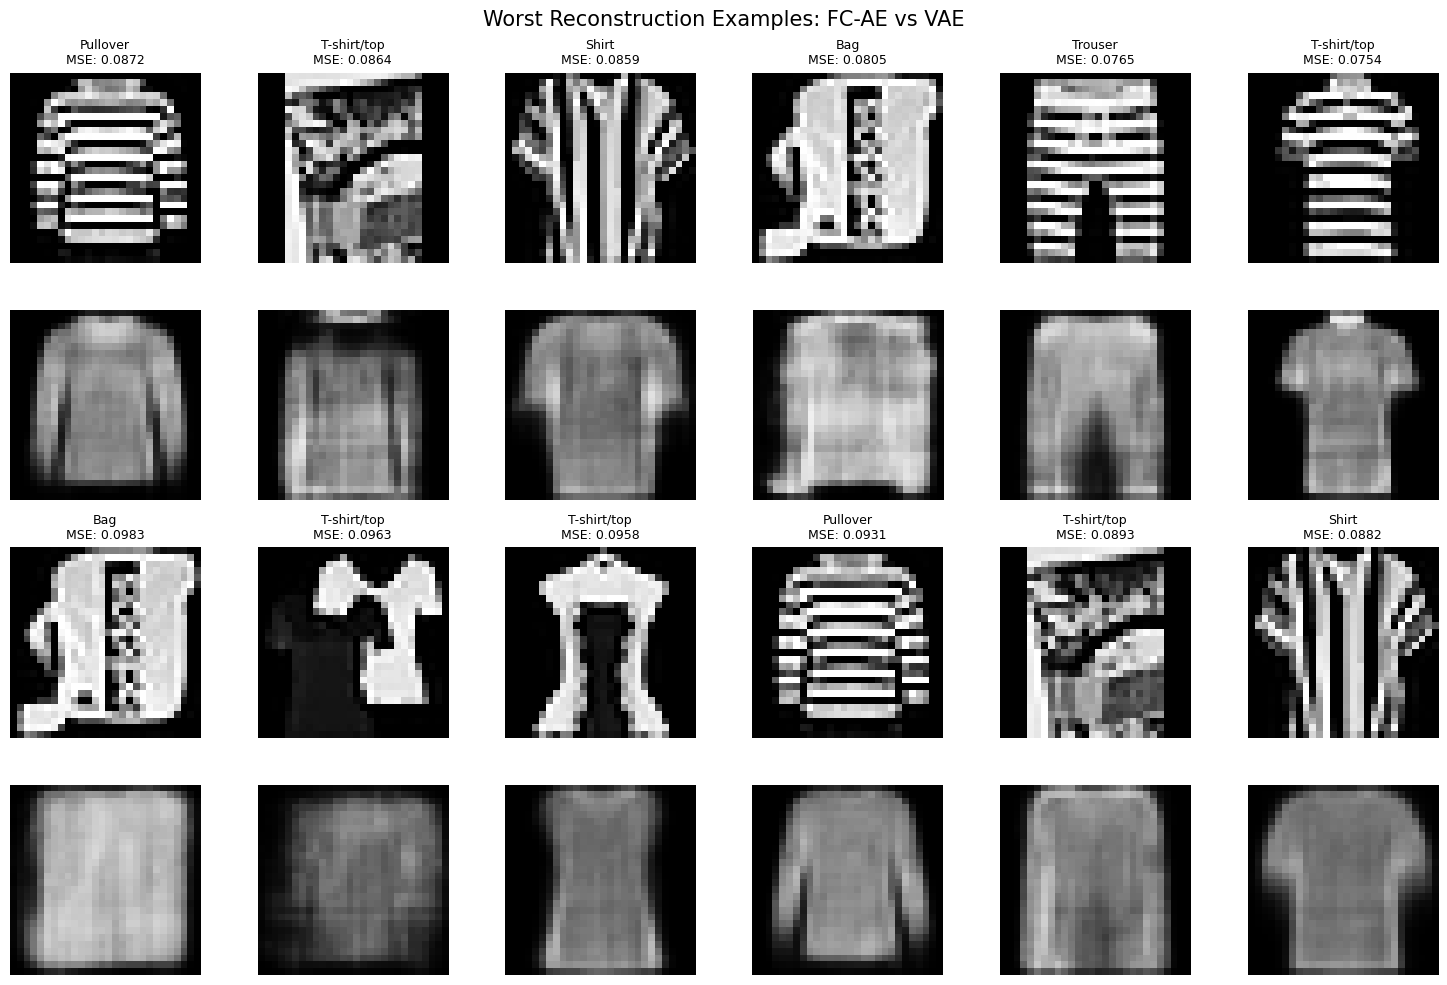

WORST RECONSTRUCTION EXAMPLES
Model  Rank  Test Index       Class  Reconstruction MSE
FC-AE     1        9067    Pullover            0.087229
FC-AE     2        3953 T-shirt/top            0.086388
FC-AE     3        7348       Shirt            0.085874
FC-AE     4        1286         Bag            0.080455
FC-AE     5        4392     Trouser            0.076498
FC-AE     6        3485 T-shirt/top            0.075365
  VAE     1        1286         Bag            0.098278
  VAE     2        6191 T-shirt/top            0.096253
  VAE     3        4193 T-shirt/top            0.095782
  VAE     4        9067    Pullover            0.093127
  VAE     5        3953 T-shirt/top            0.089342
  VAE     6        7348       Shirt            0.088180
---------------------------------------------------------------------------
Figure saved : /content/drive/MyDrive/GEN AI HWS/HW7/figures/worst_reconstruction_examples.png
CSV saved    : /content/drive/MyDrive/GEN AI HWS/HW7/metrics/worst_reco

In [25]:

# ============================================================
# HW7 - STEP 21: WORST RECONSTRUCTION EXAMPLES
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# ------------------------------------------------------------
# BLOCK A: COLLECT RECONSTRUCTION ERRORS
# ------------------------------------------------------------

fc_ae.eval()
vae.eval()

all_originals = []
all_fc_recons = []
all_vae_recons = []
all_labels = []
all_fc_errors = []
all_vae_errors = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # FC-AE reconstruction
        fc_recon = fc_ae(images)

        # VAE deterministic reconstruction
        h = vae.encoder(images)
        mu = vae.fc_mu(h)
        vae_recon = vae.decoder(mu)

        # Per-image MSE
        fc_mse = ((fc_recon - images) ** 2).mean(
            dim=(1, 2, 3)
        )

        vae_mse = ((vae_recon - images) ** 2).mean(
            dim=(1, 2, 3)
        )

        all_originals.append(images.cpu())
        all_fc_recons.append(fc_recon.cpu())
        all_vae_recons.append(vae_recon.cpu())
        all_labels.append(labels.cpu())

        all_fc_errors.append(fc_mse.cpu())
        all_vae_errors.append(vae_mse.cpu())

# Combine batches
all_originals = torch.cat(all_originals)
all_fc_recons = torch.cat(all_fc_recons)
all_vae_recons = torch.cat(all_vae_recons)
all_labels = torch.cat(all_labels)

all_fc_errors = torch.cat(all_fc_errors)
all_vae_errors = torch.cat(all_vae_errors)

# ------------------------------------------------------------
# BLOCK B: SELECT SIX WORST EXAMPLES PER MODEL
# ------------------------------------------------------------

NUM_FAILURES = 6

fc_worst_indices = torch.topk(
    all_fc_errors, NUM_FAILURES
).indices

vae_worst_indices = torch.topk(
    all_vae_errors, NUM_FAILURES
).indices

# ------------------------------------------------------------
# BLOCK C: VISUALIZE FAILURE EXAMPLES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, NUM_FAILURES,
    figsize=(15, 10)
)

for i in range(NUM_FAILURES):

    fc_idx = fc_worst_indices[i].item()
    vae_idx = vae_worst_indices[i].item()

    # FC-AE originals
    axes[0, i].imshow(
        all_originals[fc_idx].squeeze(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].set_title(
        f"{class_names[all_labels[fc_idx].item()]}\n"
        f"MSE: {all_fc_errors[fc_idx]:.4f}",
        fontsize=9
    )

    # FC-AE reconstructions
    axes[1, i].imshow(
        all_fc_recons[fc_idx].squeeze(),
        cmap="gray", vmin=0, vmax=1
    )

    # VAE originals
    axes[2, i].imshow(
        all_originals[vae_idx].squeeze(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[2, i].set_title(
        f"{class_names[all_labels[vae_idx].item()]}\n"
        f"MSE: {all_vae_errors[vae_idx]:.4f}",
        fontsize=9
    )

    # VAE reconstructions
    axes[3, i].imshow(
        all_vae_recons[vae_idx].squeeze(),
        cmap="gray", vmin=0, vmax=1
    )

    for row in range(4):
        axes[row, i].axis("off")

axes[0, 0].set_ylabel("FC Original", fontsize=11)
axes[1, 0].set_ylabel("FC Recon", fontsize=11)
axes[2, 0].set_ylabel("VAE Original", fontsize=11)
axes[3, 0].set_ylabel("VAE Recon", fontsize=11)

plt.suptitle(
    "Worst Reconstruction Examples: FC-AE vs VAE",
    fontsize=15
)

plt.tight_layout()

# ------------------------------------------------------------
# BLOCK D: SAVE FIGURE AND ERROR DETAILS
# ------------------------------------------------------------

figure_path = os.path.join(
    FIGURES_DIR,
    "worst_reconstruction_examples.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

failure_records = []

for model_name, indices, errors in [
    ("FC-AE", fc_worst_indices, all_fc_errors),
    ("VAE", vae_worst_indices, all_vae_errors)
]:

    for rank, idx in enumerate(indices.tolist(), start=1):

        failure_records.append({
            "Model": model_name,
            "Rank": rank,
            "Test Index": idx,
            "Class": class_names[all_labels[idx].item()],
            "Reconstruction MSE": errors[idx].item()
        })

failure_df = pd.DataFrame(failure_records)

csv_path = os.path.join(
    METRICS_DIR,
    "worst_reconstruction_examples.csv"
)

failure_df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# BLOCK E: VERIFICATION
# ------------------------------------------------------------

assert len(failure_df) == 12
assert os.path.isfile(figure_path)
assert os.path.isfile(csv_path)

print("=" * 75)
print("WORST RECONSTRUCTION EXAMPLES")
print("=" * 75)

print(
    failure_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("-" * 75)
print(f"Figure saved : {figure_path}")
print(f"CSV saved    : {csv_path}")
print("=" * 75)
print("PASS: Reconstruction failure analysis completed.")


In [26]:

# ============================================================
# HW7 - STEP 22: FAILURE ANALYSIS AND INTERPRETATION
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# BLOCK A: LOAD VERIFIED EXPERIMENT RESULTS
# ------------------------------------------------------------

failure_csv = os.path.join(
    METRICS_DIR, "worst_reconstruction_examples.csv"
)

class_csv = os.path.join(
    METRICS_DIR, "class_wise_reconstruction_mse.csv"
)

failures = pd.read_csv(failure_csv)
class_results = pd.read_csv(class_csv)

fc_worst = failures[failures["Model"] == "FC-AE"]
vae_worst = failures[failures["Model"] == "VAE"]

# ------------------------------------------------------------
# BLOCK B: IDENTIFY HIGH-ERROR CLASSES
# ------------------------------------------------------------

fc_hardest = class_results.loc[
    class_results["FC-AE MSE"].idxmax()
]

vae_hardest = class_results.loc[
    class_results["VAE MSE"].idxmax()
]

fc_easiest = class_results.loc[
    class_results["FC-AE MSE"].idxmin()
]

vae_easiest = class_results.loc[
    class_results["VAE MSE"].idxmin()
]

# ------------------------------------------------------------
# BLOCK C: BUILD FAILURE ANALYSIS REPORT
# ------------------------------------------------------------

report = f"""# HW7 - Autoencoder Failure Analysis

## 1. Experiment Overview

Dataset: FashionMNIST

Test images: 10,000

Models:
- Fully Connected Autoencoder (FC-AE)
- Variational Autoencoder (VAE)

Training epochs: 20

Latent dimension: 32

## 2. Overall Reconstruction Results

| Model | Test MSE |
|---|---|
| FC-AE | {fc_full_test_mse:.6f} |
| VAE | {vae_full_test_mse:.6f} |

FC-AE achieved lower reconstruction MSE.

The VAE additionally optimizes KL divergence to regularize
its latent distribution, introducing a trade-off between
reconstruction fidelity and generative capability.

## 3. Class-Wise Error Analysis

Highest average FC-AE error:
{fc_hardest['Class']} ({fc_hardest['FC-AE MSE']:.6f})

Highest average VAE error:
{vae_hardest['Class']} ({vae_hardest['VAE MSE']:.6f})

Lowest average FC-AE error:
{fc_easiest['Class']} ({fc_easiest['FC-AE MSE']:.6f})

Lowest average VAE error:
{vae_easiest['Class']} ({vae_easiest['VAE MSE']:.6f})

## 4. Worst Reconstruction Examples

The six highest-error images for each model were identified
using per-image pixel MSE.

### FC-AE

{fc_worst.to_markdown(index=False)}

### VAE

{vae_worst.to_markdown(index=False)}

## 5. Failure Categories and Diagnoses

### Category A: Loss of Fine Details

High-frequency image details, such as stripes, patterns,
and edges, can be smoothed during reconstruction.

Diagnosis:
The compressed latent representation may not preserve
all fine-grained visual information.

### Category B: Unusual Clothing Structures

Several high-error examples contain distinctive shapes
or uncommon clothing configurations.

Diagnosis:
The models may reconstruct common clothing structures
more accurately than unusual examples.

### Category C: Shape and Texture Distortion

Some reconstructed images preserve the broad silhouette
but lose internal structure and texture.

Diagnosis:
Pixel-based reconstruction objectives do not explicitly
guarantee preservation of perceptual details.

## 6. Model Comparison

FC-AE:
- Lower full-test reconstruction MSE.
- Directly optimized for pixel reconstruction.
- Does not explicitly regularize its latent distribution.

VAE:
- Higher reconstruction MSE.
- Learns a regularized probabilistic latent representation.
- Supports generating images through latent sampling.

## 7. Limitations

1. Evaluation uses FashionMNIST only.
2. Both models use fully connected architectures.
3. Results come from one training seed.
4. MSE does not fully capture perceptual image quality.
5. VAE reconstruction uses the latent mean rather than
   stochastic latent sampling.

## 8. Conclusion

The FC-AE achieved better pixel-level reconstruction
accuracy on FashionMNIST.

The VAE traded some reconstruction accuracy for a
regularized latent representation that supports sampling.

The worst reconstruction examples suggest that unusual
shapes and fine visual details remain challenging.

These findings are specific to the tested architectures,
training settings, and dataset.
"""

# ------------------------------------------------------------
# BLOCK D: SAVE REPORT
# ------------------------------------------------------------

report_path = os.path.join(
    HW7_DIR,
    "FAILURE_ANALYSIS.md"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

# ------------------------------------------------------------
# BLOCK E: VERIFY REPORT
# ------------------------------------------------------------

assert os.path.isfile(report_path)
assert len(fc_worst) == 6
assert len(vae_worst) == 6

print("=" * 70)
print("HW7 FAILURE ANALYSIS REPORT")
print("=" * 70)

print(f"FC-AE worst examples : {len(fc_worst)}")
print(f"VAE worst examples   : {len(vae_worst)}")
print(f"Total examples       : {len(failures)}")
print(f"Report saved to      : {report_path}")
print(f"Report size          : {os.path.getsize(report_path):,} bytes")

print("=" * 70)
print("PASS: Failure analysis report generated successfully.")


HW7 FAILURE ANALYSIS REPORT
FC-AE worst examples : 6
VAE worst examples   : 6
Total examples       : 12
Report saved to      : /content/drive/MyDrive/GEN AI HWS/HW7/FAILURE_ANALYSIS.md
Report size          : 3,891 bytes
PASS: Failure analysis report generated successfully.


In [27]:

# ============================================================
# HW7 - STEP 23: GENERATE METRICS.md
# ============================================================

import os
import json
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# BLOCK A: LOAD SAVED EXPERIMENT METRICS
# ------------------------------------------------------------

def load_json(filename):
    path = os.path.join(METRICS_DIR, filename)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

fc_metrics = load_json("fc_ae_metrics.json")
vae_metrics = load_json("vae_metrics.json")
comparison = load_json("fc_ae_vs_vae_comparison.json")

class_results = pd.read_csv(
    os.path.join(
        METRICS_DIR,
        "class_wise_reconstruction_mse.csv"
    )
)

failures = pd.read_csv(
    os.path.join(
        METRICS_DIR,
        "worst_reconstruction_examples.csv"
    )
)

# ------------------------------------------------------------
# BLOCK B: CALCULATE COMPARATIVE STATISTICS
# ------------------------------------------------------------

fc_mse = comparison["fc_ae_test_mse"]
vae_mse = comparison["vae_test_mse"]

relative_reduction = (
    (vae_mse - fc_mse) / vae_mse
) * 100

fc_time = fc_metrics["training_time_seconds"]
vae_time = vae_metrics["training_time_seconds"]

# ------------------------------------------------------------
# BLOCK C: BUILD METRICS REPORT
# ------------------------------------------------------------

report = f"""# Homework 7 - Experiment Metrics

## 1. Personal Parameters

| Parameter | Value |
|---|---|
| SID4 | {SID4} |
| SEED | {SEED} |
| SLICE | {SLICE} |
| HP_ID | {HP_ID} |
| CLS_A | {CLS_A} |
| CLS_B | {CLS_B} |

## 2. Dataset

| Property | Value |
|---|---|
| Dataset | FashionMNIST |
| Training images | 60,000 |
| Test images | 10,000 |
| Image dimensions | 1 x 28 x 28 |
| Classes | 10 |
| Pixel range | [0, 1] |

## 3. Model Configuration

| Configuration | FC-AE | VAE |
|---|---|---|
| Architecture | Fully Connected | Variational |
| Latent dimension | {fc_metrics['latent_dim']} | {vae_metrics['latent_dim']} |
| Parameters | {fc_metrics['total_parameters']:,} | {vae_metrics['total_parameters']:,} |
| Epochs | {fc_metrics['epochs']} | {vae_metrics['epochs']} |
| Batch size | {fc_metrics['batch_size']} | {vae_metrics['batch_size']} |
| Learning rate | {fc_metrics['learning_rate']} | {vae_metrics['learning_rate']} |
| Optimizer | Adam | Adam |
| Training objective | MSE | BCE + KL |
| KL weight | N/A | {vae_metrics['beta']} |

## 4. Reconstruction Performance

| Metric | FC-AE | VAE |
|---|---|---|
| Full test reconstruction MSE | {fc_mse:.6f} | {vae_mse:.6f} |
| Sample reconstruction MSE | {fc_metrics['sample_reconstruction_mse']:.6f} | {vae_metrics['sample_reconstruction_mse']:.6f} |
| Training time (seconds) | {fc_time:.2f} | {vae_time:.2f} |
| Best epoch | {fc_metrics['best_epoch']} | {vae_metrics['best_epoch']} |

FC-AE achieved {relative_reduction:.2f}% lower
full-test reconstruction MSE than VAE.

Both models were evaluated on the same 10,000 test images.

VAE reconstruction used the latent mean for deterministic
evaluation.

## 5. FC-AE Training Results

| Metric | Value |
|---|---|
| Final training MSE | {fc_metrics['final_train_mse']:.6f} |
| Final test MSE | {fc_metrics['final_test_mse']:.6f} |
| Best test MSE | {fc_metrics['best_test_mse']:.6f} |
| Best epoch | {fc_metrics['best_epoch']} |

## 6. VAE Training Results

| Metric | Value |
|---|---|
| Final training objective | {vae_metrics['final_train_loss']:.4f} |
| Final test objective | {vae_metrics['final_test_loss']:.4f} |
| Final test reconstruction BCE | {vae_metrics['final_test_reconstruction_bce']:.4f} |
| Final test KL divergence | {vae_metrics['final_test_kl']:.4f} |
| Best test objective | {vae_metrics['best_test_loss']:.4f} |
| Best epoch | {vae_metrics['best_epoch']} |

VAE objective values are per image.
They are not directly comparable to FC-AE MSE.

## 7. Class-Wise Reconstruction MSE

{class_results.to_markdown(index=False, floatfmt=".6f")}

## 8. Worst Reconstruction Examples

{failures.to_markdown(index=False, floatfmt=".6f")}

## 9. Interpretation

The FC-AE achieved lower pixel-level reconstruction
error than the VAE.

The VAE additionally regularizes its latent distribution,
supporting sampling of new images.

Both models had their lowest average class-wise MSE
for trousers.

The FC-AE's highest average class-wise MSE was for bags,
while the VAE's was for sandals.

The experiment uses one seed and one architecture
configuration per model. These findings should not be
generalized to all autoencoder architectures.

## 10. Saved Figures

- figures/fc_ae_loss_curve.png
- figures/fc_ae_reconstructions.png
- figures/vae_training_curves.png
- figures/vae_reconstructions.png
- figures/fc_ae_vs_vae_mse_comparison.png
- figures/vae_generated_images.png
- figures/class_wise_reconstruction_mse.png
- figures/worst_reconstruction_examples.png

## 11. Additional Artifacts

- checkpoints/fc_ae_final.pth
- checkpoints/vae_final.pth
- metrics/fc_ae_training_history.csv
- metrics/vae_training_history.csv
- metrics/fc_ae_vs_vae_comparison.json
- FAILURE_ANALYSIS.md

Report generated: {datetime.now().isoformat()}
"""

# ------------------------------------------------------------
# BLOCK D: SAVE METRICS.md
# ------------------------------------------------------------

metrics_md_path = os.path.join(
    HW7_DIR,
    "METRICS.md"
)

with open(metrics_md_path, "w", encoding="utf-8") as f:
    f.write(report)

# ------------------------------------------------------------
# BLOCK E: VERIFY
# ------------------------------------------------------------

assert os.path.isfile(metrics_md_path)
assert len(class_results) == 10
assert len(failures) == 12

with open(metrics_md_path, "r", encoding="utf-8") as f:
    saved_report = f.read()

assert "Reconstruction Performance" in saved_report
assert "Class-Wise Reconstruction MSE" in saved_report
assert "Worst Reconstruction Examples" in saved_report

print("=" * 70)
print("HW7 METRICS REPORT VERIFICATION")
print("=" * 70)

print(f"FC-AE Test MSE      : {fc_mse:.6f}")
print(f"VAE Test MSE        : {vae_mse:.6f}")
print(f"FC-AE MSE reduction : {relative_reduction:.2f}%")
print(f"Class-wise rows     : {len(class_results)}")
print(f"Failure examples    : {len(failures)}")
print(f"Report size         : {os.path.getsize(metrics_md_path):,} bytes")
print(f"Saved to            : {metrics_md_path}")

print("=" * 70)
print("PASS: METRICS.md generated successfully.")


HW7 METRICS REPORT VERIFICATION
FC-AE Test MSE      : 0.010034
VAE Test MSE        : 0.014975
FC-AE MSE reduction : 32.99%
Class-wise rows     : 10
Failure examples    : 12
Report size         : 4,615 bytes
Saved to            : /content/drive/MyDrive/GEN AI HWS/HW7/METRICS.md
PASS: METRICS.md generated successfully.


In [28]:

# ============================================================
# HW7 - STEP 24: CREATE AI_USE.md AND RUN_LOG.txt
# ============================================================

import os
import json
from datetime import datetime

assert os.path.isdir(HW7_DIR), "HW7 directory not found."

# ------------------------------------------------------------
# BLOCK A: LOAD SAVED EXPERIMENT RESULTS
# ------------------------------------------------------------

with open(os.path.join(METRICS_DIR, "fc_ae_metrics.json")) as f:
    fc = json.load(f)

with open(os.path.join(METRICS_DIR, "vae_metrics.json")) as f:
    vae_m = json.load(f)

with open(os.path.join(
    METRICS_DIR, "fc_ae_vs_vae_comparison.json"
)) as f:
    comparison = json.load(f)

# ------------------------------------------------------------
# BLOCK B: CREATE AI_USE.md
# ------------------------------------------------------------

ai_use = """# Homework 7 - AI Use Disclosure

## 1. How I Used AI

I used ChatGPT to assist with:
- Structuring the PyTorch implementation.
- Implementing FC-AE and VAE architectures.
- Defining reconstruction and KL divergence losses.
- Preparing training and evaluation code.
- Creating visualizations and metric reports.
- Debugging Google Drive path errors.
- Organizing experiment documentation.

My own work included:
- Executing the notebook in Google Colab.
- Training both models on FashionMNIST.
- Checking training outputs and model behavior.
- Comparing reconstruction metrics.
- Reviewing generated figures and failure examples.

I reviewed and tested the AI-assisted code rather than
assuming that every suggested implementation was correct.

## 2. Specific AI-Assisted Error

An earlier visualization cell attempted to use HW7_DIR
before the variable was available.

Actual error:

NameError: name 'HW7_DIR' is not defined

A subsequent folder verification also failed:

AssertionError: HW7 folder not found.
Mount Google Drive first.

## 3. How I Identified the Error

The notebook stopped when attempting to create the
figures directory.

The error traceback identified the missing HW7_DIR
variable. The directory assertion then showed that
the expected Google Drive path was not accessible.

## 4. What I Changed and Why

I verified the Google Drive connection and corrected
the working directory to:

/content/drive/MyDrive/GEN AI HWS/HW7

I then defined HW7_DIR before creating output folders.

The corrected code successfully saved figures and
experiment artifacts to the intended directory.

## 5. Verification

I verified the corrected workflow by checking:
- Successful FC-AE and VAE training.
- Finite reconstruction losses.
- Correct model input and output shapes.
- Saved checkpoints and metrics files.
- Full-test reconstruction comparison.
- Saved reconstruction and error-analysis figures.

## 6. Limitations

The experiments use one training seed and fixed
architectures. Reconstruction MSE measures pixel-level
accuracy but does not fully describe perceptual quality.

The VAE also optimizes KL divergence, so its total
training objective should not be directly compared
against the FC-AE MSE objective.

## Disclosure

This document describes AI-assisted work and observed
errors. The student should review and revise this
description to accurately reflect their own contributions.
"""

ai_path = os.path.join(HW7_DIR, "AI_USE.md")

with open(ai_path, "w", encoding="utf-8") as f:
    f.write(ai_use)

# ------------------------------------------------------------
# BLOCK C: CREATE RUN_LOG.txt
# ------------------------------------------------------------

run_log = f"""HOMEWORK 7 - EXPERIMENT RUN SUMMARY
============================================

NOTE:
This is a reconstructed summary of recorded results.
It is not the complete original console transcript.

Dataset: FashionMNIST
Training samples: 60000
Testing samples: 10000
Device: CUDA
Seed: {fc['seed']}

============================================
FC-AE TRAINING
============================================

Start: 2026-10-20T13:56:20.892249
End:   2026-10-20T13:57:46.693103

Architecture: Fully Connected Autoencoder
Parameters: {fc['total_parameters']}
Latent dimension: {fc['latent_dim']}
Epochs: {fc['epochs']}
Batch size: {fc['batch_size']}
Learning rate: {fc['learning_rate']}

"""

for i, (train, test) in enumerate(
    zip(fc_train_losses, fc_test_losses), start=1
):
    run_log += (
        f"Epoch [{i:02d}/20] | "
        f"Train MSE: {train:.6f} | "
        f"Test MSE: {test:.6f}\n"
    )

run_log += f"""
Final Train MSE: {fc['final_train_mse']:.6f}
Final Test MSE: {fc['final_test_mse']:.6f}
Best Epoch: {fc['best_epoch']}
Training Time: {fc['training_time_seconds']:.2f} seconds

PASS: FC-AE training completed.

============================================
VAE TRAINING
============================================

Start: 2026-10-20T14:48:35.180007
End:   2026-10-20T14:50:02.259064

Architecture: Variational Autoencoder
Parameters: {vae_m['total_parameters']}
Latent dimension: {vae_m['latent_dim']}
Epochs: {vae_m['epochs']}
Batch size: {vae_m['batch_size']}
Learning rate: {vae_m['learning_rate']}
Beta: {vae_m['beta']}

"""

for i in range(len(vae_train_losses)):
    run_log += (
        f"Epoch [{i+1:02d}/20] | "
        f"Train: {vae_train_losses[i]:.4f} | "
        f"Test: {vae_test_losses[i]:.4f} | "
        f"Recon: {vae_test_recon_losses[i]:.4f} | "
        f"KL: {vae_test_kl_losses[i]:.4f}\n"
    )

run_log += f"""
Final Train Loss: {vae_m['final_train_loss']:.4f}
Final Test Loss: {vae_m['final_test_loss']:.4f}
Final Test Reconstruction BCE:
{vae_m['final_test_reconstruction_bce']:.4f}
Final Test KL: {vae_m['final_test_kl']:.4f}
Best Epoch: {vae_m['best_epoch']}
Training Time: {vae_m['training_time_seconds']:.2f} seconds

PASS: VAE training completed.

============================================
FULL TEST SET COMPARISON
============================================

Test Images: {comparison['test_images']}
FC-AE MSE: {comparison['fc_ae_test_mse']:.6f}
VAE MSE: {comparison['vae_test_mse']:.6f}
Lower MSE Model: {comparison['lower_mse_model']}

PASS: Full test set comparison completed.

============================================
ERRORS ENCOUNTERED
============================================

Error 1:
NameError: name 'HW7_DIR' is not defined

Error 2:
AssertionError: HW7 folder not found.
Mount Google Drive first.

Resolution:
Verified Google Drive mount and corrected HW7_DIR.

============================================
RUN SUMMARY GENERATED
============================================

Generated: {datetime.now().isoformat()}

Original notebook console output should be
retained for full reproducibility evidence.
"""

log_path = os.path.join(HW7_DIR, "RUN_LOG.txt")

with open(log_path, "w", encoding="utf-8") as f:
    f.write(run_log)

# ------------------------------------------------------------
# BLOCK D: VERIFY BOTH FILES
# ------------------------------------------------------------

assert os.path.isfile(ai_path)
assert os.path.isfile(log_path)

with open(log_path, encoding="utf-8") as f:
    saved_log = f.read()

assert saved_log.count("Epoch [") == 40

print("=" * 65)
print("HW7 SUBMISSION DOCUMENT VERIFICATION")
print("=" * 65)

for path in [ai_path, log_path]:
    print(
        f"PASS | {os.path.basename(path)} | "
        f"{os.path.getsize(path):,} bytes"
    )

print("-" * 65)
print("FC-AE epochs recorded : 20")
print("VAE epochs recorded   : 20")
print("Total epochs recorded : 40")
print(f"Folder                : {HW7_DIR}")
print("=" * 65)
print("PASS: AI_USE.md and RUN_LOG.txt generated.")


HW7 SUBMISSION DOCUMENT VERIFICATION
PASS | AI_USE.md | 2,403 bytes
PASS | RUN_LOG.txt | 4,765 bytes
-----------------------------------------------------------------
FC-AE epochs recorded : 20
VAE epochs recorded   : 20
Total epochs recorded : 40
Folder                : /content/drive/MyDrive/GEN AI HWS/HW7
PASS: AI_USE.md and RUN_LOG.txt generated.
